In [1]:
# Cell 1: Import pustaka dan fungsi helper dari polynomial_regression.py
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline

from polynomial_regression import load_car_data

In [2]:
# Cell 2: Memuat dataset dan menampilkan 5 baris pertama
data = load_car_data()
print(f"Dimensi Dataset: {data.shape[0]} baris x {data.shape[1]} kolom")
data.head()

[INFO] Mengunduh dataset dari: https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-ML240EN-SkillsNetwork/labs/encoded_car_data.csv
Dimensi Dataset: 205 baris x 36 kolom


,diesel,gas,std,turbo,convertible,hardtop,hatchback,sedan,wagon,4wd,...,wheelbase,curbweight,enginesize,boreratio,horsepower,carlength,carwidth,citympg,highwaympg,price
0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,88.6,2548.0,130.0,3.47,111.0,168.8,64.1,21.0,27.0,13495.0
1,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,88.6,2548.0,130.0,3.47,111.0,168.8,64.1,21.0,27.0,16500.0
2,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,94.5,2823.0,152.0,2.68,154.0,171.2,65.5,19.0,26.0,16500.0
3,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,99.8,2337.0,109.0,3.19,102.0,176.6,66.2,24.0,30.0,13950.0
4,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,...,99.4,2824.0,136.0,3.19,115.0,176.6,66.4,18.0,22.0,17450.0


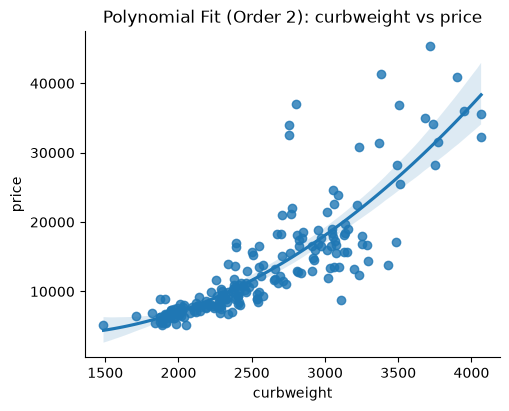

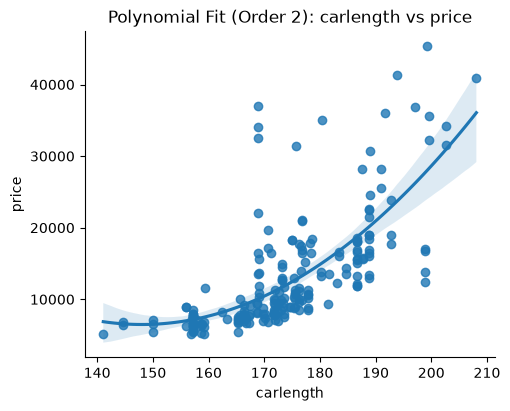

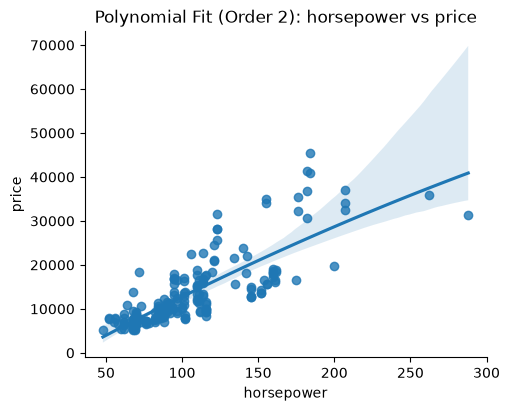

In [3]:
# Cell 3: Visualisasi hubungan non-linear (Order 2) terhadap target 'price' (Termasuk Exercise 1)
for feature in ['curbweight', 'carlength', 'horsepower']:
    if feature in data.columns:
        sns.lmplot(x=feature, y='price', data=data, order=2, height=4, aspect=1.3)
        plt.title(f'Polynomial Fit (Order 2): {feature} vs price')
        plt.show()

In [4]:
# Cell 4: Pemisahan fitur (X) dan target (y) serta Train-Test Split (70:30)
X = data.drop('price', axis=1)
y = data['price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Jumlah sampel Training :", X_train.shape[0])
print("Jumlah sampel Testing  :", X_test.shape[0])

Jumlah sampel Training : 143
Jumlah sampel Testing  : 62


In [5]:
# Cell 5: Definisi fungsi visualisasi distribusi dan evaluasi R^2 per fitur
def plot_dis(y_actual, y_pred, title='Actual vs Fitted Values'):
    plt.figure(figsize=(8, 4.5))
    sns.kdeplot(y_actual, color='r', label='Actual Value', linewidth=2)
    sns.kdeplot(y_pred, color='b', label='Fitted Values', linewidth=2)
    plt.title(title)
    plt.xlabel('Price (in dollars)')
    plt.ylabel('Proportion of Cars')
    plt.legend()
    plt.show()

def get_R2_features(model):
    features = [col for col in X.columns if col != 'three']
    r2_train, r2_test = [], []
    for feat in features:
        model.fit(X_train[[feat]], y_train)
        r2_train.append(model.score(X_train[[feat]], y_train))
        r2_test.append(model.score(X_test[[feat]], y_test))
    plt.figure(figsize=(10, 4.5))
    plt.bar(features, r2_train, label='Train', alpha=0.8)
    plt.bar(features, r2_test, label='Test', alpha=0.8)
    plt.xticks(rotation=90)
    plt.ylabel('$R^2$')
    plt.legend()
    plt.show()
    print(f"Rata-rata R^2 Train: {np.mean(r2_train):.4f} | Test: {np.mean(r2_test):.4f}")
    print(f"Maksimum R^2 Train : {np.max(r2_train):.4f} | Test: {np.max(r2_test):.4f}")

R^2 pada data Training : 0.9262722224294516
R^2 pada data Testing  : 0.8419174509630335


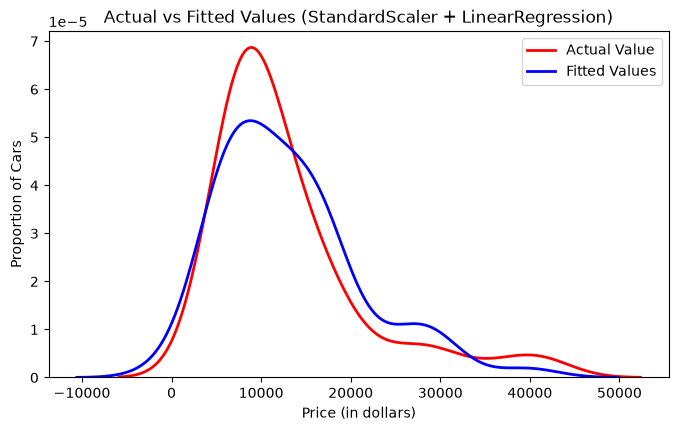

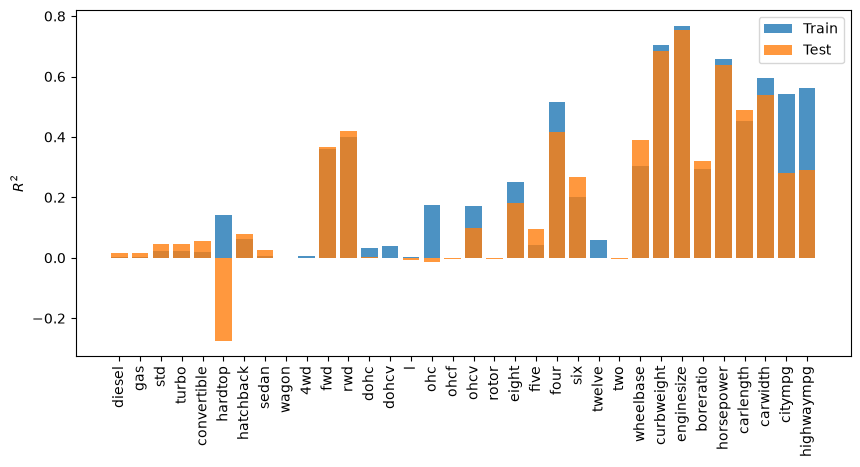

Rata-rata R^2 Train: 0.2182 | Test: 0.1824
Maksimum R^2 Train : 0.7687 | Test: 0.7535


In [6]:
# Cell 6: Baseline Multiple Linear Regression & Pipeline StandardScaler (Exercise 2 & 3)
pipe_lr = Pipeline([
    ('ss', StandardScaler()),
    ('lr', LinearRegression())
])
pipe_lr.fit(X_train, y_train)
predicted_lr = pipe_lr.predict(X_test)

print("R^2 pada data Training :", pipe_lr.score(X_train, y_train))
print("R^2 pada data Testing  :", pipe_lr.score(X_test, y_test))

plot_dis(y_test, predicted_lr, title='Actual vs Fitted Values (StandardScaler + LinearRegression)')
get_R2_features(pipe_lr)

Jumlah fitur polinomial (degree=2): 665
R^2 Training (All Features Poly)  : 0.9775944991686888
R^2 Testing  (All Features Poly)  : 0.8390684783829796


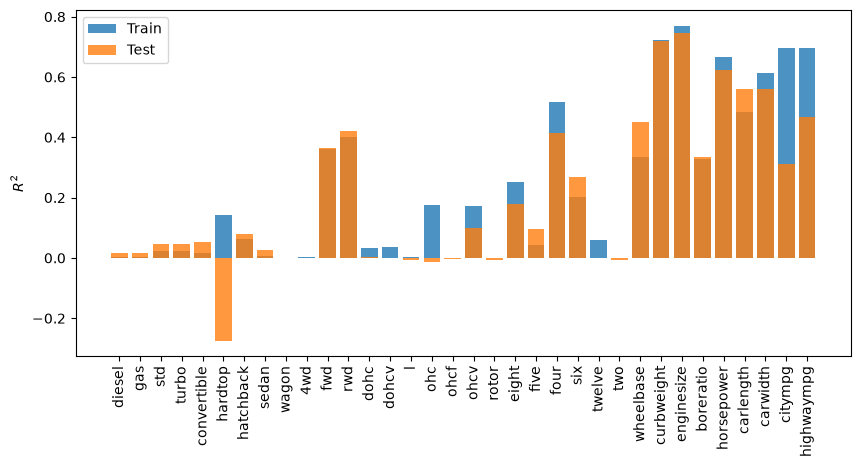

Rata-rata R^2 Train: 0.2308 | Test: 0.1939
Maksimum R^2 Train : 0.7707 | Test: 0.7463


In [7]:
# Cell 7: Transformasi PolynomialFeatures (Degree=2) pada seluruh fitur & fitur individual
poly_features = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly_features.fit_transform(X_train)
X_test_poly = poly_features.transform(X_test)

lm_poly = LinearRegression()
lm_poly.fit(X_train_poly, y_train)
print("Jumlah fitur polinomial (degree=2):", X_train_poly.shape[1])
print("R^2 Training (All Features Poly)  :", lm_poly.score(X_train_poly, y_train))
print("R^2 Testing  (All Features Poly)  :", lm_poly.score(X_test_poly, y_test))

# Evaluasi Polynomial (Degree=2) pada masing-masing fitur individual
pipe_poly_indiv = Pipeline([
    ('polynomial', PolynomialFeatures(include_bias=False, degree=2)),
    ('model', LinearRegression())
])
get_R2_features(pipe_poly_indiv)

Parameter Terbaik: {'polynomial__degree': 1}
R^2 Terbaik pada Data Testing: 0.8419174509630336


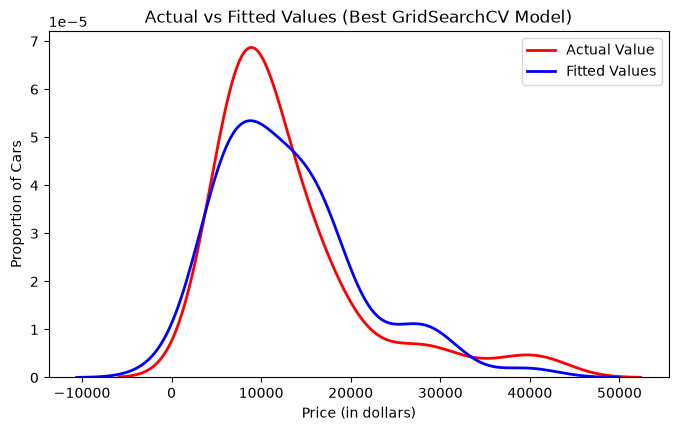

In [8]:
# Cell 8: Hyperparameter Tuning dengan GridSearchCV & Pipeline (Degree 1, 2, 3)
pipe_grid = Pipeline([
    ('scaler', StandardScaler()),
    ('polynomial', PolynomialFeatures(include_bias=False, degree=2)),
    ('model', LinearRegression())
])
param_grid = {'polynomial__degree': [1, 2, 3]}

search = GridSearchCV(pipe_grid, param_grid, cv=5, n_jobs=1)
search.fit(X_train, y_train)

best_model = search.best_estimator_
print("Parameter Terbaik:", search.best_params_)
print("R^2 Terbaik pada Data Testing:", best_model.score(X_test, y_test))

predicted_best = best_model.predict(X_test)
plot_dis(y_test, predicted_best, title='Actual vs Fitted Values (Best GridSearchCV Model)')

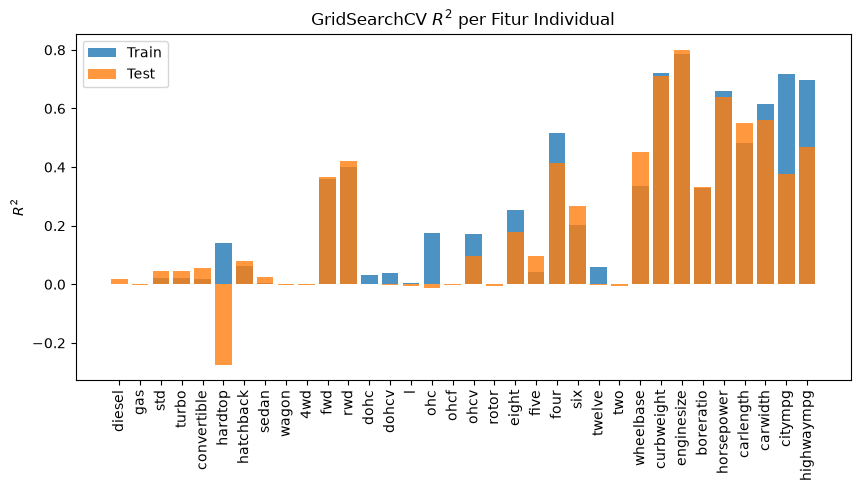

Rata-rata R^2 Train: 0.2314 | Test: 0.1966
Maksimum R^2 Train : 0.7860 | Test: 0.8012


In [9]:
# Cell 9: GridSearchCV untuk setiap fitur individual (Exercise 4)
features = [col for col in X.columns if col != 'three']
r2_train_gs, r2_test_gs = [], []

for feat in features:
    param_grid_indiv = {
        'polynomial__degree': [1, 2, 3, 4, 5],
        'model__positive': [True, False]
    }
    pipe_indiv = Pipeline([
        ('polynomial', PolynomialFeatures(include_bias=False, degree=2)),
        ('model', LinearRegression())
    ])
    search_indiv = GridSearchCV(pipe_indiv, param_grid_indiv, cv=5, n_jobs=1)
    search_indiv.fit(X_train[[feat]], y_train)
    best_indiv = search_indiv.best_estimator_
    
    r2_train_gs.append(best_indiv.score(X_train[[feat]], y_train))
    r2_test_gs.append(best_indiv.score(X_test[[feat]], y_test))

plt.figure(figsize=(10, 4.5))
plt.bar(features, r2_train_gs, label='Train', alpha=0.8)
plt.bar(features, r2_test_gs, label='Test', alpha=0.8)
plt.xticks(rotation=90)
plt.ylabel('$R^2$')
plt.title('GridSearchCV $R^2$ per Fitur Individual')
plt.legend()
plt.show()

print(f"Rata-rata R^2 Train: {np.mean(r2_train_gs):.4f} | Test: {np.mean(r2_test_gs):.4f}")
print(f"Maksimum R^2 Train : {np.max(r2_train_gs):.4f} | Test: {np.max(r2_test_gs):.4f}")